In [1]:
from google.colab import files
uploaded = files.upload()
SRC_FILE = list(uploaded.keys())[0]
print("Using:", SRC_FILE)

Saving Tableau BlinkIT Grocery Project U16955293080 (4).xlsx to Tableau BlinkIT Grocery Project U16955293080 (4).xlsx
Using: Tableau BlinkIT Grocery Project U16955293080 (4).xlsx


In [2]:
import os, bisect
import numpy as np
import pandas as pd

OUT_DIR = "/content/output"
os.makedirs(OUT_DIR, exist_ok=True)

raw = pd.read_excel(SRC_FILE) if SRC_FILE.endswith((".xlsx", ".xls")) else pd.read_csv(SRC_FILE)
print("Original columns:", list(raw.columns))

# Keep only what is useful: item id, category, price. Drop the rest.
# One clean price per item (the same item has a different price in each store)
catalog = (raw.groupby("Item_Identifier")
              .agg(item_type=("Item_Type", "first"), item_price=("Item_MRP", "mean"))
              .reset_index().rename(columns={"Item_Identifier": "item_id"}))
catalog["item_price"] = catalog["item_price"].round(0).astype(int)
catalog["is_small_item"] = (catalog["item_price"] < 75).astype(int)
catalog["price_band"] = pd.cut(catalog["item_price"], [0, 50, 100, 150, 1000],
                               labels=["<50", "50-100", "100-150", "150+"]).astype(str)

print("\nCatalog shape:", catalog.shape)
print(catalog.item_price.describe().round(1))
catalog.head()

Original columns: ['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Identifier', 'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type', 'Item_Outlet_Sales']

Catalog shape: (1559, 5)
count    1559.0
mean      141.0
std        62.1
min        32.0
25%        94.0
50%       142.0
75%       186.0
max       265.0
Name: item_price, dtype: float64


,item_id,item_type,item_price,is_small_item,price_band
0,DRA12,Soft Drinks,142,0,100-150
1,DRA24,Soft Drinks,164,0,150+
2,DRA59,Soft Drinks,185,0,150+
3,DRB01,Soft Drinks,190,0,150+
4,DRB13,Soft Drinks,190,0,150+


In [3]:
# ---------------- CONFIG (state these in your paper) ----------------
SEED = 42
GRID = 10                    # 10 x 10 cells, each 300 m x 300 m (3 km x 3 km area)
THRESHOLD = 149              # min order value (Rs) for free delivery
WARMUP_DAYS = 7              # only for history features, not in output
TOTAL_DAYS = 65              # 7 warm-up + 57 data + 1 buffer
TRAIN_LAST_DAY = 48          # days 7..48 train, 49..63 test
ORDERS_PER_DAY = 1200
OPEN_HOUR, CLOSE_HOUR = 7, 23
N_USERS = 4000
WAITS = [2, 5, 8, 10, 15]                  # minutes
RADII = {300: 0, 600: 1, 900: 2}           # metres -> cell distance
# ---------------------------------------------------------------------
rng = np.random.default_rng(SEED)

# ---- Grid and zones ----
rr, cc = np.divmod(np.arange(GRID * GRID), GRID)
d_hub = np.minimum(np.hypot(rr - 2, cc - 2), np.hypot(rr - 7, cc - 7))
d_cen = np.hypot(rr - 4.5, cc - 4.5)
zone = np.empty(GRID * GRID, dtype=object)
for i in range(GRID * GRID):
    noise = rng.normal(0, 0.6)
    if d_cen[i] + noise < 1.8:   zone[i] = "commercial"
    elif d_hub[i] + noise < 2.2: zone[i] = "dense_residential"
    elif d_hub[i] + noise < 4.0: zone[i] = "normal_residential"
    else:                        zone[i] = "quiet"
ZW = {"dense_residential": 4.0, "normal_residential": 2.0, "commercial": 2.5, "quiet": 0.4}
zw = np.array([ZW[z] for z in zone])

def prof(peaks):
    h = np.arange(24, dtype=float); p = np.full(24, 0.05)
    for centre_h, width, amp in peaks:
        p += amp * np.exp(-0.5 * ((h - centre_h) / width) ** 2)
    p[(h < OPEN_HOUR) | (h >= CLOSE_HOUR)] = 0
    return p / p.sum()
PROF_RES = prof([(9, 1.2, 0.4), (13, 1.3, 0.6), (20, 1.6, 1.0)])
PROF_COM = prof([(9, 1.0, 0.3), (13, 1.2, 1.0), (17, 1.2, 0.4)])

cell_users = rng.choice(GRID * GRID, size=N_USERS, p=zw / zw.sum())
user_activity = rng.lognormal(0, 0.8, N_USERS)
users_by_cell = {c: np.where(cell_users == c)[0] for c in range(GRID * GRID)}

# ---- Simulate orders ----
rows = []
for day in range(TOTAL_DAYS):
    dow = day % 7
    weekend = dow >= 5
    lam = np.zeros((24, GRID * GRID))
    for c in range(GRID * GRID):
        p = PROF_COM if zone[c] == "commercial" else PROF_RES
        f = (0.5 if weekend else 1.0) if zone[c] == "commercial" else (1.2 if weekend else 1.0)
        lam[:, c] = zw[c] * p * f
    lam *= ORDERS_PER_DAY / lam.sum()
    counts = rng.poisson(lam)
    for h, c in zip(*np.nonzero(counts)):
        for _ in range(counts[h, c]):
            us = users_by_cell[c]
            if len(us) == 0: continue
            w = user_activity[us]; u = rng.choice(us, p=w / w.sum())
            n_items = rng.choice([1, 2, 3, 4], p=[0.65, 0.22, 0.10, 0.03])
            items = catalog.sample(n_items, random_state=int(rng.integers(1e9)))
            t = day * 1440 + h * 60 + rng.uniform(0, 60)
            rows.append((t, day, h, dow, c, int(u), int(items.item_price.sum()), n_items))
orders = pd.DataFrame(rows, columns=["t", "day", "hour", "dow", "cell", "user", "value", "n_items"])
orders = orders.sort_values("t").reset_index(drop=True)
orders["order_id"] = np.arange(1, len(orders) + 1)
orders["small"] = (orders.value < THRESHOLD).astype(int)

# ---- Lookup structures ----
def neighbours(cell, k):
    r, c = divmod(cell, GRID)
    return [r_ * GRID + c_ for r_ in range(max(0, r - k), min(GRID, r + k + 1))
            for c_ in range(max(0, c - k), min(GRID, c + k + 1))]
NB = {(c, k): neighbours(c, k) for c in range(GRID * GRID) for k in (0, 1, 2)}
small = orders[orders.small == 1]
s_times = {c: g.t.values for c, g in small.groupby("cell")}
s_users = {c: g.user.values for c, g in small.groupby("cell")}
a_times = {c: g.t.values for c, g in orders.groupby("cell")}
EMPTY = np.array([])
cnt = np.zeros((TOTAL_DAYS, 24, GRID * GRID))
for d, h, c in zip(orders.day, orders.hour, orders.cell): cnt[d, h, c] += 1
cum = np.cumsum(cnt, axis=0)

# ---- Features (past only) + labels (future) ----
user_n, user_s, base_rows = {}, {}, []
for r in orders.itertuples(index=False):
    pn, ps = user_n.get(r.user, 0), user_s.get(r.user, 0)
    user_n[r.user] = pn + 1; user_s[r.user] = ps + r.small
    if r.small == 0 or r.day < WARMUP_DAYS or r.day > TOTAL_DAYS - 2: continue
    avg_hist = cum[r.day - 1, r.hour, r.cell] / r.day
    ao = a_times.get(r.cell, EMPTY)
    last15_cell = bisect.bisect_left(ao, r.t) - bisect.bisect_left(ao, r.t - 15)
    f = dict(order_id=r.order_id, user_id=r.user, day=r.day,
             hour=r.hour, day_of_week=r.dow, is_weekend=int(r.dow >= 5),
             is_peak_hour=int(r.hour in (12, 13, 19, 20, 21)),
             grid_cell_id=r.cell, grid_row=r.cell // GRID, grid_col=r.cell % GRID,
             zone_type=zone[r.cell], order_value=r.value, n_items=r.n_items,
             orders_in_cell_last_15min=last15_cell,
             avg_orders_in_cell_this_hour=round(avg_hist, 3),
             user_past_order_count=pn,
             user_small_order_ratio=round(ps / pn, 3) if pn else 0.0)
    ttp = {}
    for m, k in RADII.items():
        cnt15, first = 0, np.inf
        for cell in NB[(r.cell, k)]:
            st = s_times.get(cell, EMPTY)
            cnt15 += bisect.bisect_left(st, r.t) - bisect.bisect_left(st, r.t - 15)
            su = s_users.get(cell, EMPTY)
            i = bisect.bisect_right(st, r.t)
            while i < len(st) and st[i] - r.t <= 15:
                if su[i] != r.user: first = min(first, st[i] - r.t); break
                i += 1
        f[f"small_orders_{m}m_last_15min"] = cnt15
        ttp[m] = first
    base_rows.append((f, ttp))

out = []
for f, ttp in base_rows:
    for m in RADII:
        for w in WAITS:
            row = dict(f); row["wait_minutes"] = w; row["radius_m"] = m
            row["partner_found"] = int(ttp[m] <= w)
            out.append(row)
df = pd.DataFrame(out)
df["split"] = np.where(df.day <= TRAIN_LAST_DAY, "train", "test")
df = df.drop(columns=["day"])

print("Orders simulated:", len(orders), "| small share: %.1f%%" % (100 * orders.small.mean()))
print("Dataset shape:", df.shape, "| unique small orders:", df.order_id.nunique())
df.head()

Orders simulated: 78514 | small share: 36.5%
Dataset shape: (375675, 23) | unique small orders: 25045


,order_id,user_id,hour,day_of_week,is_weekend,is_peak_hour,grid_cell_id,grid_row,grid_col,zone_type,...,avg_orders_in_cell_this_hour,user_past_order_count,user_small_order_ratio,small_orders_300m_last_15min,small_orders_600m_last_15min,small_orders_900m_last_15min,wait_minutes,radius_m,partner_found,split
0,8477,3723,7,0,0,0,55,5,5,commercial,...,0.0,0,0.0,0,0,0,2,300,0,train
1,8477,3723,7,0,0,0,55,5,5,commercial,...,0.0,0,0.0,0,0,0,5,300,0,train
2,8477,3723,7,0,0,0,55,5,5,commercial,...,0.0,0,0.0,0,0,0,8,300,0,train
3,8477,3723,7,0,0,0,55,5,5,commercial,...,0.0,0,0.0,0,0,0,10,300,0,train
4,8477,3723,7,0,0,0,55,5,5,commercial,...,0.0,0,0.0,0,0,0,15,300,0,train


In [4]:
df.to_csv(f"{OUT_DIR}/training_dataset.csv", index=False)
catalog.to_csv(f"{OUT_DIR}/item_catalog_clean.csv", index=False)
files.download(f"{OUT_DIR}/training_dataset.csv")
files.download(f"{OUT_DIR}/item_catalog_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Constant columns:", [c for c in df.columns if df[c].nunique() == 1])
print("\nData types:"); print(df.dtypes)
display(df.describe().T.round(2))

# Logic checks that must hold
assert (df.order_value < 149).all(), "Found non-small orders"
assert df.partner_found.isin([0, 1]).all()
assert (df.groupby("order_id").size() == 15).all(), "Each order should have 15 rows"

# Label logic: waiting longer or searching wider can never lose a partner
m1 = df.sort_values("wait_minutes").groupby(["order_id", "radius_m"]).partner_found \
       .apply(lambda s: (s.diff().dropna() >= 0).all())
m2 = df.sort_values("radius_m").groupby(["order_id", "wait_minutes"]).partner_found \
       .apply(lambda s: (s.diff().dropna() >= 0).all())
print("\nLabel monotone in wait:", m1.all(), "| in radius:", m2.all())

# Class balance and outliers
print("\nPartner-found rate: %.3f" % df.partner_found.mean())
num = df.select_dtypes("number").drop(columns=["order_id", "user_id"])
q1, q3 = num.quantile(.25), num.quantile(.75); iqr = q3 - q1
print("\nShare of outliers per column (IQR rule):")
print(((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).mean().round(3).sort_values(ascending=False).head(8))
print("\nAll checks passed")

Shape: (375675, 23)
Missing values: 0
Duplicate rows: 0
Constant columns: []

Data types:
order_id                          int64
user_id                           int64
hour                              int64
day_of_week                       int64
is_weekend                        int64
is_peak_hour                      int64
grid_cell_id                      int64
grid_row                          int64
grid_col                          int64
zone_type                        object
order_value                       int64
n_items                           int64
orders_in_cell_last_15min         int64
avg_orders_in_cell_this_hour    float64
user_past_order_count             int64
user_small_order_ratio          float64
small_orders_300m_last_15min      int64
small_orders_600m_last_15min      int64
small_orders_900m_last_15min      int64
wait_minutes                      int64
radius_m                          int64
partner_found                     int64
split                         

,count,mean,std,min,25%,50%,75%,max
order_id,375675.0,42972.47,19789.82,8477.0,25854.00,42971.00,60060.00,77351.00
user_id,375675.0,1976.99,1146.89,1.0,989.00,1966.00,2960.00,3999.00
hour,375675.0,15.69,4.48,7.0,12.00,16.00,20.00,22.00
day_of_week,375675.0,2.96,2.02,0.0,1.00,3.00,5.00,6.00
is_weekend,375675.0,0.28,0.45,0.0,0.00,0.00,1.00,1.00
is_peak_hour,375675.0,0.50,0.50,0.0,0.00,0.00,1.00,1.00
grid_cell_id,375675.0,50.34,29.17,0.0,24.00,51.00,76.00,99.00
grid_row,375675.0,4.58,2.78,0.0,2.00,5.00,7.00,9.00
grid_col,375675.0,4.57,2.79,0.0,2.00,5.00,7.00,9.00
order_value,375675.0,93.74,33.14,32.0,62.00,98.00,120.00,148.00



Label monotone in wait: True | in radius: True

Partner-found rate: 0.320

Share of outliers per column (IQR rule):
small_orders_300m_last_15min    0.113
user_small_order_ratio          0.106
small_orders_600m_last_15min    0.083
user_past_order_count           0.056
n_items                         0.040
small_orders_900m_last_15min    0.021
orders_in_cell_last_15min       0.010
avg_orders_in_cell_this_hour    0.004
dtype: float64

All checks passed


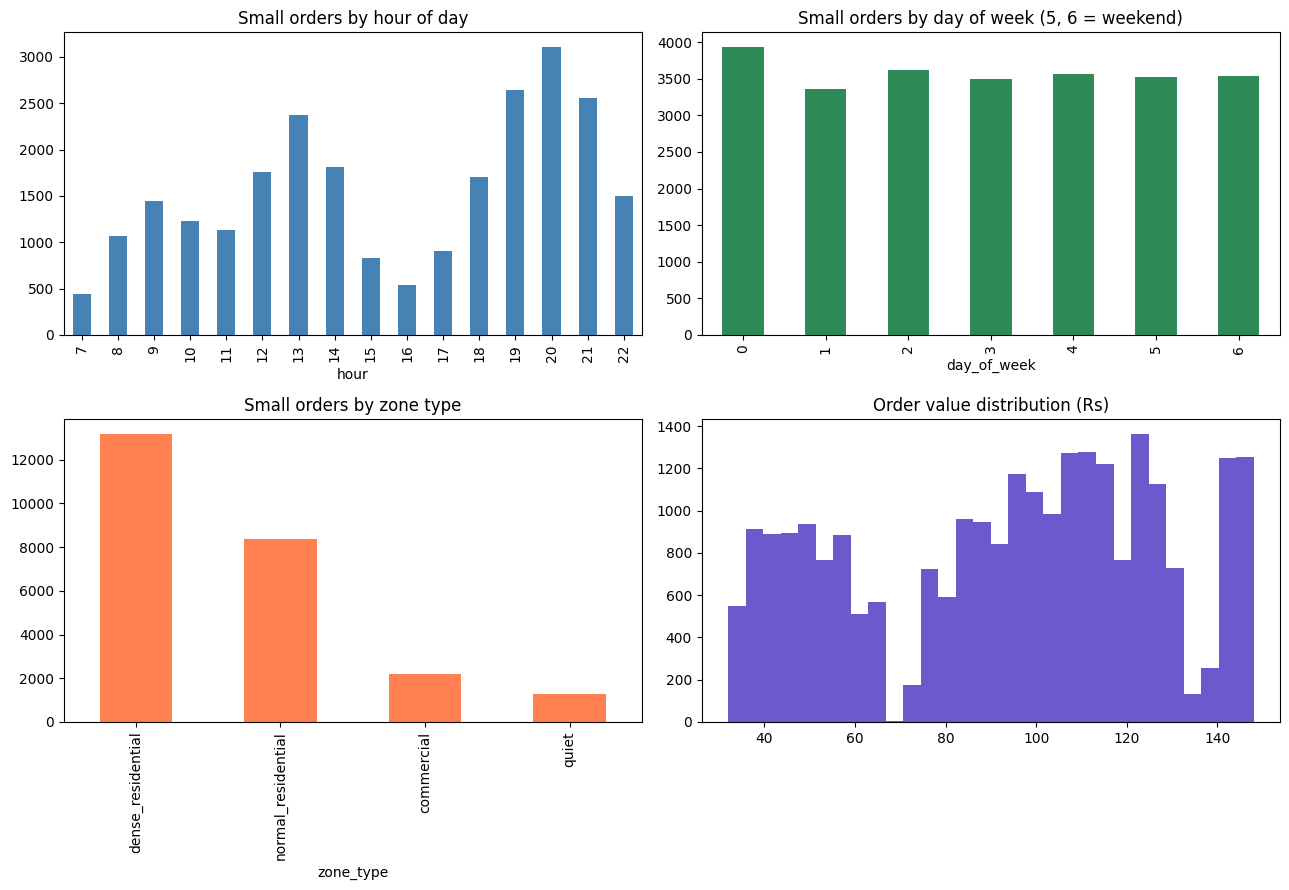

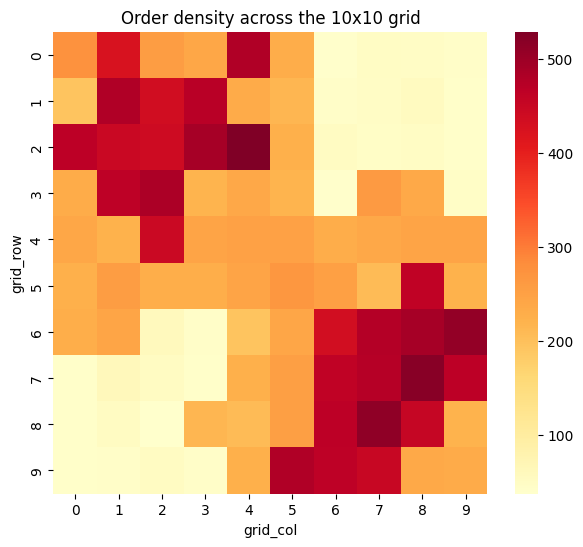

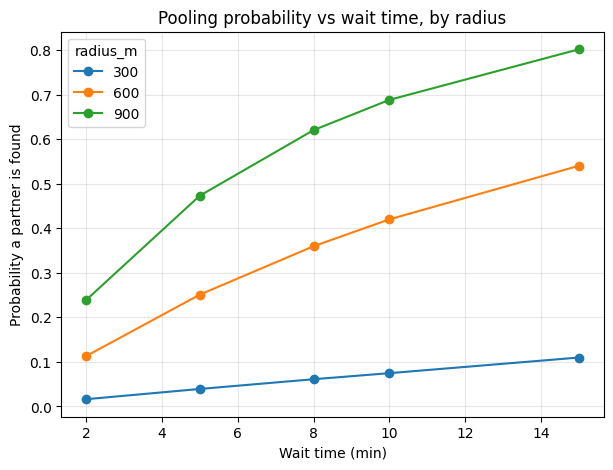

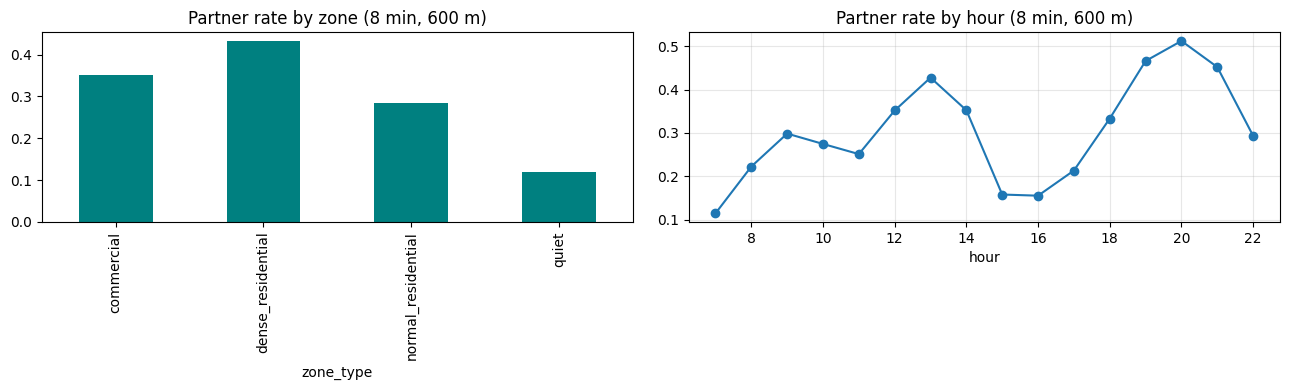

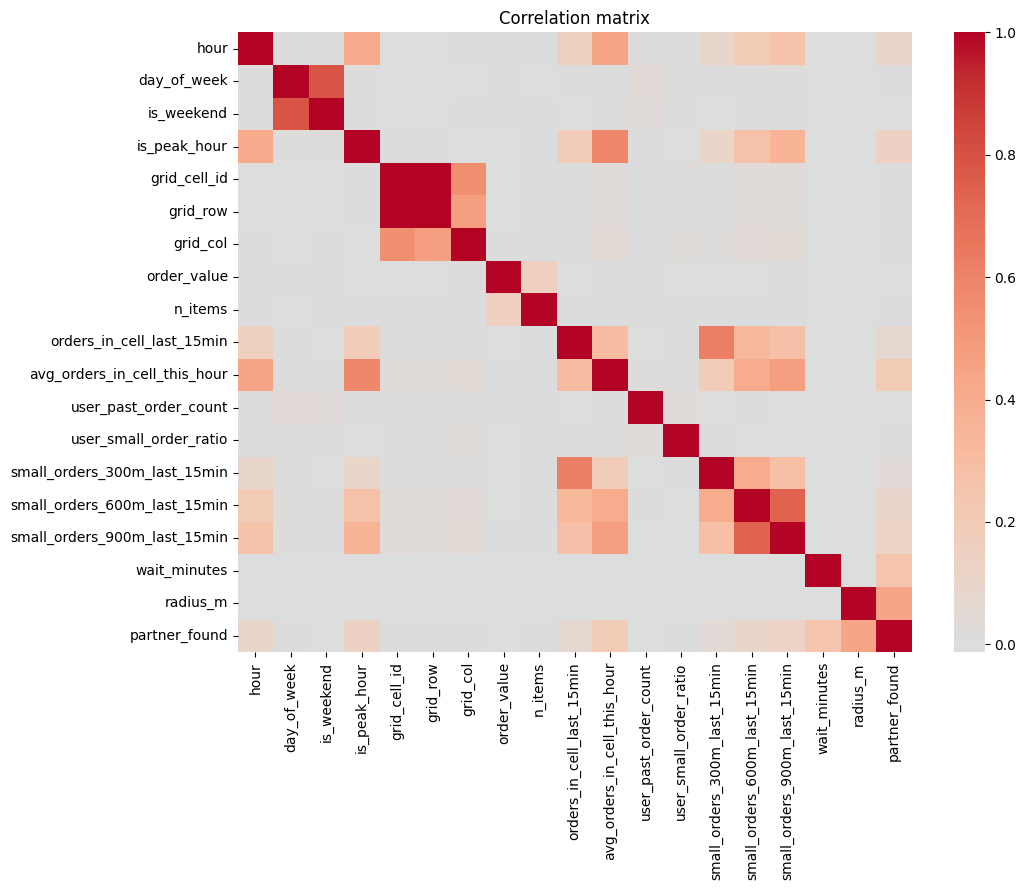

radius_m                        0.441
wait_minutes                    0.259
avg_orders_in_cell_this_hour    0.200
is_peak_hour                    0.140
small_orders_900m_last_15min    0.127
small_orders_600m_last_15min    0.101
hour                            0.094
orders_in_cell_last_15min       0.067
small_orders_300m_last_15min    0.040
grid_col                        0.018
grid_cell_id                    0.008
grid_row                        0.006
day_of_week                     0.005
is_weekend                      0.001
user_past_order_count           0.001
order_value                    -0.004
user_small_order_ratio         -0.007
n_items                        -0.008
Name: partner_found, dtype: float64


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
one = df.drop_duplicates("order_id")      # one row per small order

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
one.groupby("hour").size().plot(kind="bar", ax=ax[0, 0], color="steelblue")
ax[0, 0].set_title("Small orders by hour of day")
one.groupby("day_of_week").size().plot(kind="bar", ax=ax[0, 1], color="seagreen")
ax[0, 1].set_title("Small orders by day of week (5, 6 = weekend)")
one.zone_type.value_counts().plot(kind="bar", ax=ax[1, 0], color="coral")
ax[1, 0].set_title("Small orders by zone type")
ax[1, 1].hist(one.order_value, bins=30, color="slateblue")
ax[1, 1].set_title("Order value distribution (Rs)")
plt.tight_layout(); plt.savefig("eda_demand.png", dpi=200); plt.show()

grid = one.groupby(["grid_row", "grid_col"]).size().unstack(fill_value=0)
plt.figure(figsize=(7, 6)); sns.heatmap(grid, cmap="YlOrRd")
plt.title("Order density across the 10x10 grid"); plt.savefig("eda_heatmap.png", dpi=200); plt.show()

# The key trade-off figure
pivot = df.groupby(["radius_m", "wait_minutes"]).partner_found.mean().unstack()
pivot.T.plot(marker="o", figsize=(7, 5))
plt.ylabel("Probability a partner is found"); plt.xlabel("Wait time (min)")
plt.title("Pooling probability vs wait time, by radius"); plt.grid(alpha=0.3)
plt.savefig("eda_tradeoff.png", dpi=200); plt.show()

# Why a fixed rule can't fit everywhere
sub = df[(df.wait_minutes == 8) & (df.radius_m == 600)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sub.groupby("zone_type").partner_found.mean().plot(kind="bar", ax=ax[0], color="teal")
ax[0].set_title("Partner rate by zone (8 min, 600 m)")
sub.groupby("hour").partner_found.mean().plot(marker="o", ax=ax[1])
ax[1].set_title("Partner rate by hour (8 min, 600 m)"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig("eda_zone_hour.png", dpi=200); plt.show()

# Correlations
num_eda = [c for c in df.select_dtypes("number").columns if c not in ["order_id", "user_id"]]
corr = df[num_eda].corr()
plt.figure(figsize=(11, 9)); sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.tight_layout(); plt.savefig("eda_corr.png", dpi=200); plt.show()
print(corr["partner_found"].drop("partner_found").sort_values(ascending=False).round(3))

In [7]:
df2 = df.copy()

# Cyclical hour (23:00 and 00:00 are close, raw hour says they're far apart)
df2["hour_sin"] = np.sin(2 * np.pi * df2.hour / 24)
df2["hour_cos"] = np.cos(2 * np.pi * df2.hour / 24)

# Recent small orders inside the radius actually chosen
df2["recent_in_chosen_radius"] = np.select(
    [df2.radius_m == 300, df2.radius_m == 600, df2.radius_m == 900],
    [df2.small_orders_300m_last_15min, df2.small_orders_600m_last_15min,
     df2.small_orders_900m_last_15min])

# Expected arrivals during the wait = recent rate x wait time
df2["expected_arrivals"] = df2.recent_in_chosen_radius / 15 * df2.wait_minutes

# Is it busier than usual right now? Clip extreme values using the TRAIN split only
df2["busy_ratio"] = df2.orders_in_cell_last_15min / (df2.avg_orders_in_cell_this_hour / 4 + 1e-3)
cap = df2.loc[df2.split == "train", "busy_ratio"].quantile(0.99)
df2["busy_ratio"] = df2.busy_ratio.clip(upper=cap)

# Search area (cells) interacting with wait time
df2["wait_x_cells"] = df2.wait_minutes * df2.radius_m.map({300: 1, 600: 9, 900: 25})

# Simple flag for the busiest zone type
df2["is_dense_zone"] = (df2.zone_type == "dense_residential").astype(int)

print("busy_ratio cap:", round(cap, 2))
display(df2[["recent_in_chosen_radius", "expected_arrivals", "busy_ratio", "wait_x_cells"]].describe().round(2))

busy_ratio cap: 10.44


,recent_in_chosen_radius,expected_arrivals,busy_ratio,wait_x_cells
count,375675.00,375675.00,375675.00,375675.00
mean,1.03,0.55,0.97,93.33
std,1.45,0.93,1.97,104.84
min,0.00,0.00,0.00,2.00
25%,0.00,0.00,0.00,10.00
50%,0.00,0.00,0.00,50.00
75%,2.00,0.67,1.41,135.00
max,15.00,15.00,10.44,375.00


Redundant (dropped): []


,mutual_info,rf_importance
wait_x_cells,0.1572,0.2805
radius_m,0.1083,0.1666
expected_arrivals,0.0967,0.1341
avg_orders_in_cell_this_hour,0.0326,0.0718
wait_minutes,0.0410,0.0711
recent_in_chosen_radius,0.0694,0.0539
order_value,0.0026,0.0210
user_past_order_count,0.0000,0.0200
user_small_order_ratio,0.0032,0.0182
is_peak_hour,0.0143,0.0176


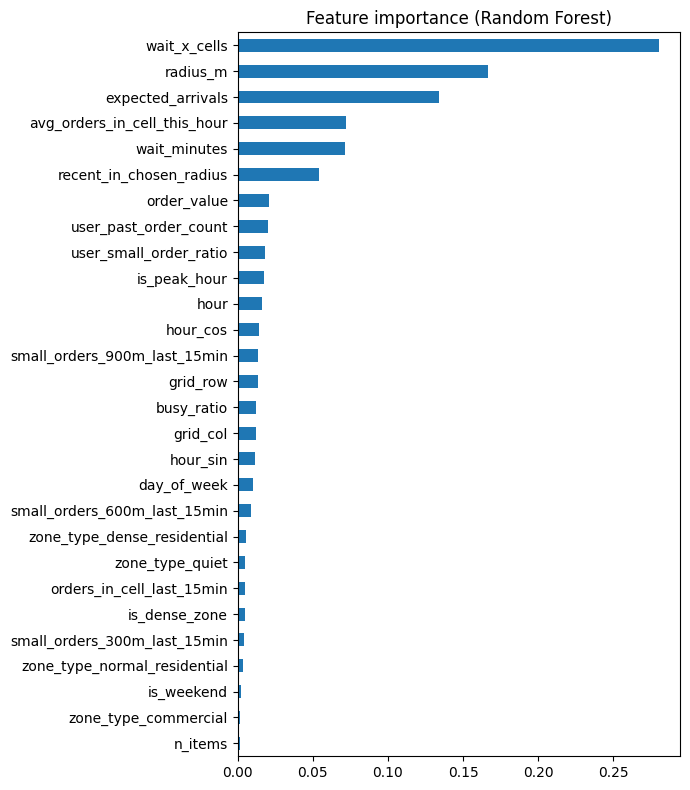

Weak features (candidates to drop): ['small_orders_300m_last_15min', 'is_weekend']

FINAL_FEATURES (23):
['hour', 'day_of_week', 'is_peak_hour', 'grid_row', 'grid_col', 'order_value', 'n_items', 'orders_in_cell_last_15min', 'avg_orders_in_cell_this_hour', 'user_past_order_count', 'user_small_order_ratio', 'small_orders_600m_last_15min', 'small_orders_900m_last_15min', 'wait_minutes', 'radius_m', 'hour_sin', 'hour_cos', 'recent_in_chosen_radius', 'expected_arrivals', 'busy_ratio', 'wait_x_cells', 'is_dense_zone', 'zone_type']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

TARGET = "partner_found"
NEVER = ["order_id", "user_id", "split", TARGET, "grid_cell_id"]   # identifiers and label
FORCE_KEEP = ["wait_minutes", "radius_m"]                           # the decision inputs
cands = [c for c in df2.columns if c not in NEVER and c != "zone_type"]
train = df2[df2.split == "train"]          # selection uses TRAIN data only

# 1) Remove near-duplicate features (|corr| > 0.95)
corr = train[cands].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
redundant = [c for c in upper.columns if c not in FORCE_KEEP and (upper[c] > 0.95).any()]
print("Redundant (dropped):", redundant)
cands = [c for c in cands if c not in redundant]

# 2) Rank by mutual information and Random Forest importance
samp = train.sample(40000, random_state=42)
X = pd.get_dummies(samp[cands + ["zone_type"]], columns=["zone_type"]).astype(float)
y = samp[TARGET]
mi = pd.Series(mutual_info_classif(X, y, random_state=42), index=X.columns)
rf = RandomForestClassifier(100, max_depth=10, n_jobs=-1, random_state=42).fit(X, y)
rfi = pd.Series(rf.feature_importances_, index=X.columns)
rank = pd.DataFrame({"mutual_info": mi, "rf_importance": rfi}).sort_values("rf_importance", ascending=False)
display(rank.round(4))

rank["rf_importance"].sort_values().plot(kind="barh", figsize=(7, 8), title="Feature importance (Random Forest)")
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=200); plt.show()

# 3) Drop features that carry almost no signal on BOTH measures
weak = [c for c in rank.index if rank.loc[c, "mutual_info"] < 0.001 and rank.loc[c, "rf_importance"] < 0.005
        and c not in FORCE_KEEP and not c.startswith("zone_type_")]
print("Weak features (candidates to drop):", weak)

FINAL_FEATURES = [c for c in cands if c not in weak] + ["zone_type"]
print("\nFINAL_FEATURES (%d):" % len(FINAL_FEATURES)); print(FINAL_FEATURES)

df2.to_csv(f"{OUT_DIR}/training_dataset_final.csv", index=False)
files.download(f"{OUT_DIR}/training_dataset_final.csv")

In [10]:
import pandas as pd, numpy as np, time, json, joblib
import matplotlib.pyplot as plt
from google.colab import files

try:
    df2                       # reuse if it already exists in this session
    df = df2
except NameError:
    up = files.upload()       # upload training_dataset_final.csv
    df = pd.read_csv(list(up.keys())[0])
print(df.shape)

(375675, 30)


In [11]:
TARGET = "partner_found"

ORIGINAL_FEATURES = ['hour','day_of_week','is_weekend','is_peak_hour','grid_row','grid_col','zone_type',
    'order_value','n_items','orders_in_cell_last_15min','avg_orders_in_cell_this_hour',
    'user_past_order_count','user_small_order_ratio','small_orders_300m_last_15min',
    'small_orders_600m_last_15min','small_orders_900m_last_15min','wait_minutes','radius_m']

FINAL_FEATURES = ['hour','day_of_week','is_peak_hour','grid_row','grid_col','order_value','n_items',
    'orders_in_cell_last_15min','avg_orders_in_cell_this_hour','user_past_order_count',
    'user_small_order_ratio','small_orders_600m_last_15min','small_orders_900m_last_15min',
    'wait_minutes','radius_m','hour_sin','hour_cos','recent_in_chosen_radius','expected_arrivals',
    'busy_ratio','wait_x_cells','is_dense_zone','zone_type']

assert len(FINAL_FEATURES) == 23
assert all(c in df.columns for c in FINAL_FEATURES + ORIGINAL_FEATURES), "Missing columns"

train = df[df.split == "train"]
test = df[df.split == "test"]          # never used for tuning or feature selection
y_train, y_test = train[TARGET], test[TARGET]
print("Train:", len(train), "| Test:", len(test))
print("Positive rate  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

Train: 277635 | Test: 98040
Positive rate  train: 0.321  test: 0.318


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, brier_score_loss)

def make_pipe(model, feats, scale=False):
    cat = [c for c in feats if c == "zone_type"]
    num = [c for c in feats if c != "zone_type"]
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat),
                             ("num", StandardScaler() if scale else "passthrough", num)])
    return Pipeline([("pre", pre), ("model", model)])

def get_models(feats):
    return {
     "Logistic Regression": make_pipe(LogisticRegression(max_iter=2000), feats, scale=True),
     "Random Forest": make_pipe(RandomForestClassifier(n_estimators=100, max_depth=12,
                         min_samples_leaf=20, n_jobs=-1, random_state=42), feats),
     "XGBoost": make_pipe(XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                         subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                         random_state=42, n_jobs=-1), feats)}

def score(name, fset, p):
    pred = (p >= 0.5).astype(int)
    return {"Model": name, "Features": fset,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, p),
            "Log-loss": log_loss(y_test, np.clip(p, 1e-6, 1 - 1e-6)),
            "Brier": brier_score_loss(y_test, p)}

results, fitted, probs = [], {}, {}

# Baseline 1: always predict the average
results.append(score("Majority class", "-", np.full(len(y_test), y_train.mean())))

# Baseline 2: fixed-rule lookup. Knows only wait and radius, no context at all.
lookup = train.groupby(["wait_minutes", "radius_m"])[TARGET].mean()
p_lookup = test.set_index(["wait_minutes", "radius_m"]).index.map(lookup).values.astype(float)
results.append(score("Fixed-rule lookup (wait, radius only)", "wait, radius", p_lookup))
probs[("Fixed-rule lookup", "-")] = p_lookup

for fset, feats in [("Original (18)", ORIGINAL_FEATURES), ("Final (23)", FINAL_FEATURES)]:
    for name, pipe in get_models(feats).items():
        t0 = time.time()
        pipe.fit(train[feats], y_train)
        p = pipe.predict_proba(test[feats])[:, 1]
        r = score(name, fset, p); r["Train sec"] = round(time.time() - t0, 1)
        results.append(r); fitted[(name, fset)] = pipe; probs[(name, fset)] = p
        print(f"done: {name:20s} {fset:14s} AUC={r['ROC-AUC']:.4f}  ({r['Train sec']}s)")

res = pd.DataFrame(results).round(4)
res.to_csv("model_comparison.csv", index=False)
display(res)

done: Logistic Regression  Original (18)  AUC=0.8430  (2.2s)
done: Random Forest        Original (18)  AUC=0.8518  (49.4s)
done: XGBoost              Original (18)  AUC=0.8536  (5.6s)
done: Logistic Regression  Final (23)     AUC=0.8452  (2.0s)
done: Random Forest        Final (23)     AUC=0.8539  (33.5s)
done: XGBoost              Final (23)     AUC=0.8531  (6.2s)


,Model,Features,Accuracy,Precision,Recall,F1,ROC-AUC,Log-loss,Brier,Train sec
0,Majority class,-,0.6824,0.0000,0.0000,0.0000,0.5000,0.6250,0.2167,NaN
1,"Fixed-rule lookup (wait, radius only)","wait, radius",0.7686,0.6615,0.5555,0.6038,0.8248,0.4682,0.1544,NaN
2,Logistic Regression,Original (18),0.7865,0.6920,0.5906,0.6373,0.8430,0.4466,0.1458,2.2
3,Random Forest,Original (18),0.7923,0.7126,0.5796,0.6393,0.8518,0.4431,0.1433,49.4
4,XGBoost,Original (18),0.7944,0.6996,0.6179,0.6562,0.8536,0.4341,0.1407,5.6
5,Logistic Regression,Final (23),0.7871,0.7019,0.5731,0.6310,0.8452,0.4441,0.1448,2.0
6,Random Forest,Final (23),0.7935,0.7038,0.6036,0.6499,0.8539,0.4339,0.1408,33.5
7,XGBoost,Final (23),0.7942,0.6991,0.6176,0.6559,0.8531,0.4350,0.1411,6.2


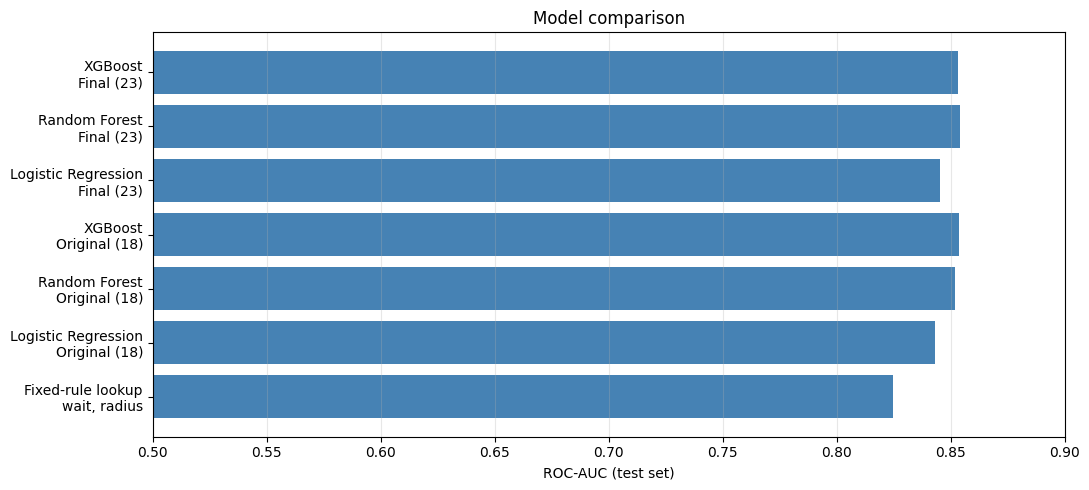

In [13]:
plot = res[res.Model != "Majority class"].copy()
plot["label"] = plot.Model.str.replace(" (wait, radius only)", "", regex=False) + "\n" + plot.Features
plt.figure(figsize=(11, 5))
plt.barh(plot.label, plot["ROC-AUC"], color="steelblue")
plt.xlim(0.5, 0.9); plt.xlabel("ROC-AUC (test set)"); plt.title("Model comparison")
plt.grid(axis="x", alpha=0.3); plt.tight_layout(); plt.savefig("model_comparison.png", dpi=200); plt.show()

Best model: ('Random Forest', 'Final (23)')


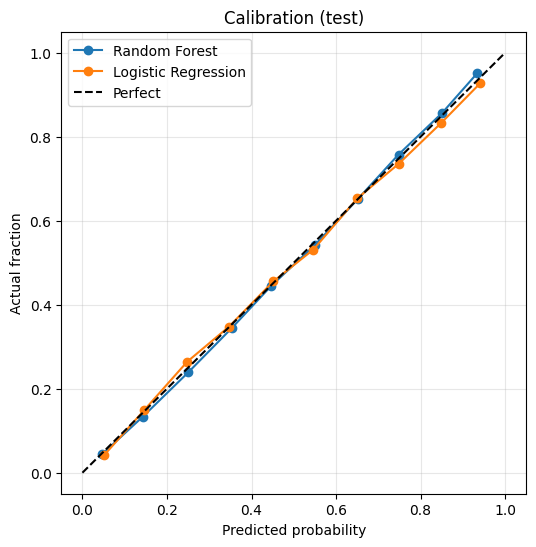

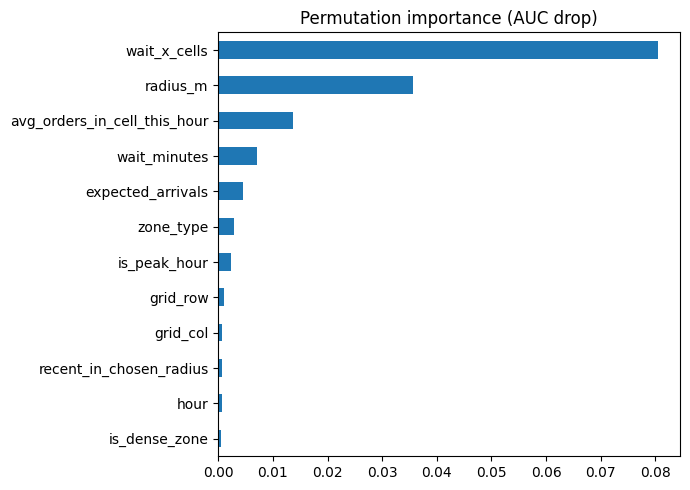

zone_type
commercial            0.856
dense_residential     0.849
normal_residential    0.850
quiet                 0.829
dtype: float64


/tmp/ipykernel_3057/2549593542.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(tmp.groupby("zone_type").apply(lambda g: roc_auc_score(g[TARGET], g["p"])).round(3))


In [18]:
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

best = max([k for k in fitted if k[1].startswith("Final")], key=lambda k: roc_auc_score(y_test, probs[k]))
print("Best model:", best)

# 1) Calibration: do predicted probabilities match reality? (the decision layer depends on this)
plt.figure(figsize=(6, 6))
for k in [best, ("Logistic Regression", "Final (23)")]:
    fp, mp = calibration_curve(y_test, probs[k], n_bins=10)
    plt.plot(mp, fp, marker="o", label=k[0])
plt.plot([0, 1], [0, 1], "k--", label="Perfect")
plt.xlabel("Predicted probability"); plt.ylabel("Actual fraction")
plt.title("Calibration (test)"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("calibration.png", dpi=200); plt.show()

# 2) Permutation importance: which features the best model really relies on
samp = test.sample(10000, random_state=42)
pi = permutation_importance(fitted[best], samp[FINAL_FEATURES], samp[TARGET],
                            scoring="roc_auc", n_repeats=3, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FINAL_FEATURES).sort_values()
imp.tail(12).plot(kind="barh", figsize=(7, 5), title="Permutation importance (AUC drop)")
plt.tight_layout(); plt.savefig("importance.png", dpi=200); plt.show()

# 3) Does it work in every zone?
tmp = test.copy(); tmp["p"] = probs[best]
print(tmp.groupby("zone_type").apply(lambda g: roc_auc_score(g[TARGET], g["p"])).round(3))

In [17]:
joblib.dump(fitted[best], "model.pkl")
json.dump({"features": FINAL_FEATURES, "waits": [2, 5, 8, 10, 15], "radii": [300, 600, 900],
           "best_model": best[0]}, open("model_meta.json", "w"))
for f in ["model.pkl", "model_meta.json", "model_comparison.csv", "model_comparison.png",
          "calibration.png", "importance.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
orders.to_csv("orders_events.csv", index=False)
files.download("orders_events.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
import pandas as pd, numpy as np, bisect, joblib
import matplotlib.pyplot as plt
from google.colab import files

up = files.upload()                                   # choose orders_events.csv
events = pd.read_csv(list(up.keys())[0])
try:
    model = fitted[("Random Forest", "Final (23)")]
except NameError:
    model = joblib.load("model.pkl")                  # upload model.pkl first if needed

TARGET = "partner_found"
train = df[df.split == "train"]
test = df[df.split == "test"].copy()
test["p"] = model.predict_proba(test[FINAL_FEATURES])[:, 1]
print(events.shape, "| test orders:", test.order_id.nunique())

Saving orders_events.csv to orders_events (1).csv
(78514, 10) | test orders: 6536


In [21]:
GRID=10; THRESHOLD=149; FEE=40; MAXW=15
DETOUR_MIN = 2.0          # extra minutes per cell of partner distance  (ASSUMPTION: try 2, 5, 8)
LAM = 2.0                 # Rs value of one minute of delay             (ASSUMPTION)
WAITS=[2,5,8,10,15]; RADII=[300,600,900]; KOF={300:0,600:1,900:2}

small = events[events.small == 1]
s_times={c:g.t.values for c,g in small.groupby("cell")}
s_users={c:g.user.values for c,g in small.groupby("cell")}
s_vals ={c:g.value.values for c,g in small.groupby("cell")}
EMPTY=np.array([])

def neighbours(cell,k):
    r,c=divmod(cell,GRID)
    return [a*GRID+b for a in range(max(0,r-k),min(GRID,r+k+1)) for b in range(max(0,c-k),min(GRID,c+k+1))]

def first_partner(row,k):
    """earliest later small order from a different user inside the radius"""
    best=(np.inf,np.nan,0); r0,c0=divmod(row.cell,GRID)
    for cell in neighbours(row.cell,k):
        st=s_times.get(cell,EMPTY); su=s_users.get(cell,EMPTY); sv=s_vals.get(cell,EMPTY)
        i=bisect.bisect_right(st,row.t)
        while i<len(st) and st[i]-row.t<=MAXW:
            if su[i]!=row.user:
                if st[i]-row.t<best[0]:
                    r1,c1=divmod(cell,GRID); best=(st[i]-row.t,sv[i],max(abs(r1-r0),abs(c1-c0)))
                break
            i+=1
    return best

def saving(v,pv):
    comb=v+pv
    return np.where(comb>=THRESHOLD, FEE, FEE*pv/comb)

ids_train=set(train.order_id); ids_test=set(test.order_id)
foc=events[(events.small==1)&events.order_id.isin(ids_train|ids_test)]
rec={r.order_id:[first_partner(r,k) for k in (0,1,2)] for r in foc.itertuples(index=False)}
foc=foc.set_index("order_id")

# Sanity check: recomputed timings must reproduce the dataset labels
chk=test.copy()
chk["ttp"]=[rec[o][KOF[r]][0] for o,r in zip(chk.order_id,chk.radius_m)]
print("Label reproduced:", ((chk.ttp<=chk.wait_minutes).astype(int)==chk[TARGET]).mean())

Label reproduced: 1.0


In [23]:
# Expected delay-if-found and partner values come from TRAIN orders only
tr=[(w,r,rec[o][KOF[r]][0]+DETOUR_MIN*rec[o][KOF[r]][2])
    for o in ids_train for r in RADII for w in WAITS if rec[o][KOF[r]][0]<=w]
mean_dly=pd.DataFrame(tr,columns=["w","r","d"]).groupby(["w","r"]).d.mean()
pv_train=foc.loc[list(ids_train),"value"].values

T=test.pivot_table(index="order_id",columns=["radius_m","wait_minutes"],values="p")
oid=T.index.values
vals=foc.loc[oid,"value"].values
one=test.drop_duplicates("order_id").set_index("order_id").loc[oid]
zone=one.zone_type.values
combos=[(w,r) for r in RADII for w in WAITS]

# What REALLY happened for every order under every wait/radius combo
SAV=np.zeros((len(oid),len(combos))); DEL=np.zeros_like(SAV); FND=np.zeros_like(SAV)
for j,(w,r) in enumerate(combos):
    k=KOF[r]
    ttp=np.array([rec[o][k][0] for o in oid]); pv=np.array([rec[o][k][1] for o in oid])
    dd=np.array([rec[o][k][2] for o in oid]); f=ttp<=w
    FND[:,j]=f; DEL[:,j]=np.where(f,ttp+DETOUR_MIN*dd,w); SAV[:,j]=np.where(f,saving(vals,np.nan_to_num(pv)),0)

# What the smart policy EXPECTS (from model probabilities)
P=np.column_stack([T[(r,w)].values for (w,r) in combos])
es_map={v:saving(np.full(len(pv_train),v),pv_train).mean() for v in np.unique(vals)}
Es=np.array([es_map[v] for v in vals])[:,None]*P
MT=np.array([mean_dly[(w,r)] for (w,r) in combos])[None,:]
ED=P*MT+(1-P)*np.array([w for (w,r) in combos])[None,:]

def smart_choice(lam):
    score=Es-lam*ED
    return np.where(score.max(axis=1)>0, score.argmax(axis=1), -1)     # -1 = dispatch now

def outcome(choice):
    n=len(oid); idx=np.arange(n); m=choice>=0; c=np.where(m,choice,0)
    return (np.where(m,SAV[idx,c],0), np.where(m,DEL[idx,c],0), np.where(m,FND[idx,c],0), m)

def summarise(name,choice):
    s,d,f,m=outcome(choice)
    return dict(Policy=name, pooled_pct=100*f.mean(), avg_saving=s.mean(), avg_delay=d.mean(),
                wasted_wait_pct=100*(m&(f==0)).mean(), net=s.mean()-LAM*d.mean())

In [24]:
rows=[summarise("No pooling",np.full(len(oid),-1))]
for (w,r) in [(5,300),(10,600),(15,900)]:
    rows.append(summarise(f"Fixed {w}min/{r}m",np.full(len(oid),combos.index((w,r)))))
rows.append(summarise(f"Smart (lambda={LAM})",smart_choice(LAM)))
display(pd.DataFrame(rows).round(2))

fx=[]
for j,(w,r) in enumerate(combos):
    s,d,f,m=outcome(np.full(len(oid),j)); fx.append((w,r,s.mean(),d.mean(),s.mean()-LAM*d.mean()))
fx=pd.DataFrame(fx,columns=["w","r","saving","delay","net"])
print("Best fixed rule (picked on test data, so a favourable baseline):", fx.loc[fx.net.idxmax(),["w","r"]].tolist())

,Policy,pooled_pct,avg_saving,avg_delay,wasted_wait_pct,net
0,No pooling,0.00,0.00,0.00,0.00,0.00
1,Fixed 5min/300m,3.87,1.39,4.90,96.13,-8.41
2,Fixed 10min/600m,41.49,14.85,8.39,58.51,-1.92
3,Fixed 15min/900m,79.88,28.59,9.41,20.12,9.77
4,Smart (lambda=2.0),69.37,25.00,7.39,23.50,10.23


Best fixed rule (picked on test data, so a favourable baseline): [15.0, 900.0]


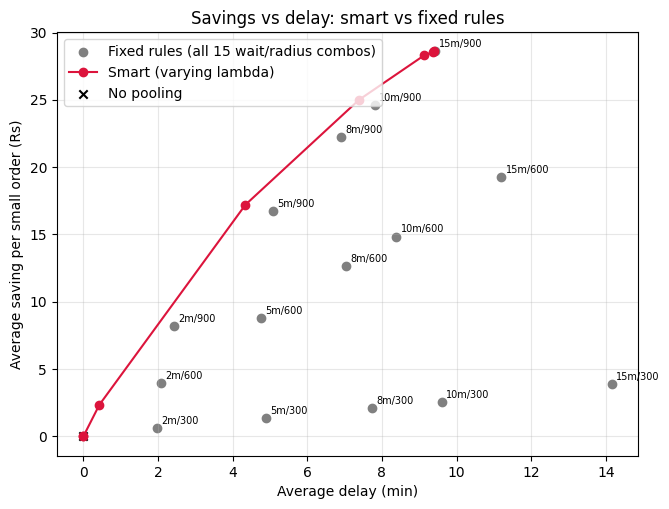

,lambda,smart_net,best_fixed_net
0,0.25,26.24,26.24
1,0.50,23.87,23.89
2,1.00,19.17,19.18
3,2.00,10.23,9.77
4,3.00,4.18,1.52
5,5.00,0.20,0.00
6,8.00,0.00,0.00
7,12.00,0.00,0.00


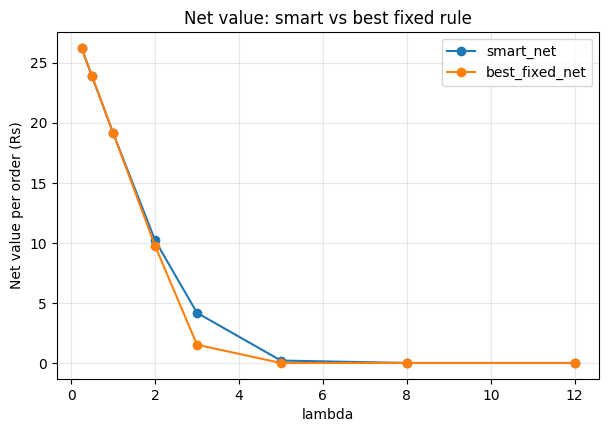

,smart_net,fixed_net,smart_delay,fixed_delay
zone,,,,
commercial,11.47,11.56,8.38,9.09
dense_residential,12.71,13.16,7.62,8.71
normal_residential,7.53,6.65,7.55,10.12
quiet,-0.15,-8.12,2.13,12.61


Smart dispatched immediately: 7.1%
(15, 900)    3540
(8, 900)     1660
(10, 900)     517
(2, 900)      248
(5, 900)      105
Name: count, dtype: int64


In [25]:
lams=[0.25,0.5,1,2,3,5,8,12]
curve=[]
for lam in lams:
    s_,d_,f_,m_=outcome(smart_choice(lam)); curve.append((lam,s_.mean(),d_.mean(),s_.mean()-lam*d_.mean()))
curve=pd.DataFrame(curve,columns=["lam","saving","delay","net"])

plt.figure(figsize=(7.5,5.5))
plt.scatter(fx.delay,fx.saving,c="gray",label="Fixed rules (all 15 wait/radius combos)")
for _,r_ in fx.iterrows(): plt.annotate(f"{int(r_.w)}m/{int(r_.r)}",(r_.delay,r_.saving),fontsize=7,xytext=(3,3),textcoords="offset points")
plt.plot(curve.delay,curve.saving,"o-",c="crimson",label="Smart (varying lambda)")
plt.scatter([0],[0],c="black",marker="x",label="No pooling")
plt.xlabel("Average delay (min)"); plt.ylabel("Average saving per small order (Rs)")
plt.title("Savings vs delay: smart vs fixed rules"); plt.grid(alpha=0.3); plt.legend()
plt.savefig("tradeoff_frontier.png",dpi=200); plt.show()

nets=[]
for lam in lams:
    bf=max([outcome(np.full(len(oid),j))[0].mean()-lam*outcome(np.full(len(oid),j))[1].mean() for j in range(len(combos))]+[0.0])
    nets.append((lam,curve.set_index("lam").loc[lam,"net"],bf))
nets=pd.DataFrame(nets,columns=["lambda","smart_net","best_fixed_net"]); display(nets.round(2))
nets.set_index("lambda").plot(marker="o",figsize=(7,4.5)); plt.ylabel("Net value per order (Rs)")
plt.title("Net value: smart vs best fixed rule"); plt.grid(alpha=0.3)
plt.savefig("net_vs_lambda.png",dpi=200); plt.show()

ch=smart_choice(LAM); s_,d_,f_,m_=outcome(ch)
bj=fx.net.idxmax(); sb,db,fb,mb=outcome(np.full(len(oid),bj))
zt=pd.DataFrame({"zone":zone,"smart_net":s_-LAM*d_,"fixed_net":sb-LAM*db,
                 "smart_delay":d_,"fixed_delay":db}).groupby("zone").mean().round(2)
display(zt)
print("Smart dispatched immediately: %.1f%%"%(100*(ch==-1).mean()))
print(pd.Series([combos[j] for j in ch[ch>=0]]).value_counts().head(8))

,detour,lam,smart_net,best_fixed_net,gain,best_fixed_rule,dispatch_now_pct,pct_radius_900,pct_radius_600,pct_radius_300
0,0,0.5,25.08,25.10,-0.02,15min/900m,0.0,100.0,0.0,0.0
1,0,1.0,21.57,21.60,-0.02,15min/900m,0.1,100.0,0.0,0.0
2,0,2.0,14.63,14.60,0.03,15min/900m,4.1,100.0,0.0,0.0
3,0,3.0,9.13,7.61,1.53,15min/900m,14.7,100.0,0.0,0.0
4,0,5.0,3.20,0.00,3.20,no pooling,49.0,100.0,0.0,0.0
5,2,0.5,23.87,23.89,-0.02,15min/900m,0.0,100.0,0.0,0.0
6,2,1.0,19.17,19.18,-0.01,15min/900m,0.3,100.0,0.0,0.0
7,2,2.0,10.23,9.77,0.45,15min/900m,7.1,100.0,0.0,0.0
8,2,3.0,4.18,1.52,2.66,8min/900m,32.8,100.0,0.0,0.0
9,2,5.0,0.20,0.00,0.20,no pooling,90.8,99.7,0.3,0.0


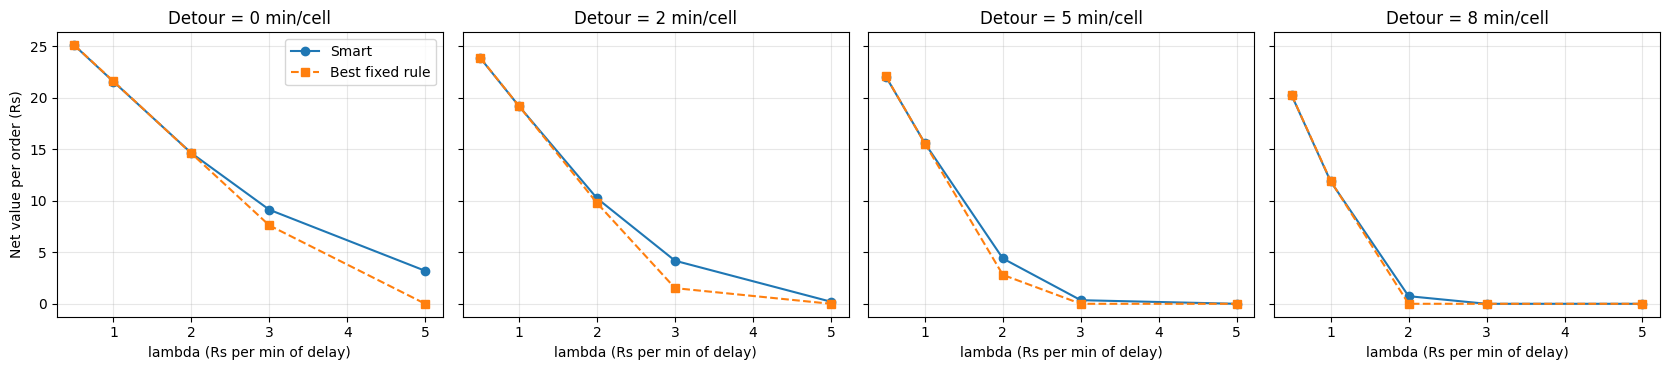

In [26]:
def run_sensitivity(detour, lams=(0.5, 1, 2, 3, 5)):
    # expected delay-if-found under this detour cost (train orders only)
    tr = [(w, r, rec[o][KOF[r]][0] + detour * rec[o][KOF[r]][2])
          for o in ids_train for r in RADII for w in WAITS if rec[o][KOF[r]][0] <= w]
    md = pd.DataFrame(tr, columns=["w", "r", "d"]).groupby(["w", "r"]).d.mean()

    # realised delay under this detour cost
    DEL_ = np.zeros_like(SAV)
    for j, (w, r) in enumerate(combos):
        k = KOF[r]
        ttp = np.array([rec[o][k][0] for o in oid]); dd = np.array([rec[o][k][2] for o in oid])
        DEL_[:, j] = np.where(ttp <= w, ttp + detour * dd, w)
    MT_ = np.array([md[(w, r)] for (w, r) in combos])[None, :]
    ED_ = P * MT_ + (1 - P) * np.array([w for (w, r) in combos])[None, :]

    n = len(oid); idx = np.arange(n)
    def out(choice):
        m = choice >= 0; c = np.where(m, choice, 0)
        return np.where(m, SAV[idx, c], 0), np.where(m, DEL_[idx, c], 0)

    rows = []
    for lam in lams:
        score = Es - lam * ED_
        ch = np.where(score.max(axis=1) > 0, score.argmax(axis=1), -1)
        s, d = out(ch); smart = s.mean() - lam * d.mean()
        fixed = [(out(np.full(n, j))[0].mean() - lam * out(np.full(n, j))[1].mean(), j)
                 for j in range(len(combos))]
        bf, bj = max(fixed)
        if bf < 0: bf, bj = 0.0, -1            # "no pooling" is the best fixed choice
        used = [combos[j][1] for j in ch[ch >= 0]]
        rows.append(dict(detour=detour, lam=lam, smart_net=round(smart, 2),
            best_fixed_net=round(bf, 2), gain=round(smart - bf, 2),
            best_fixed_rule="no pooling" if bj < 0 else f"{combos[bj][0]}min/{combos[bj][1]}m",
            dispatch_now_pct=round(100 * (ch == -1).mean(), 1),
            pct_radius_900=round(100 * np.mean(np.array(used) == 900), 1) if used else 0,
            pct_radius_600=round(100 * np.mean(np.array(used) == 600), 1) if used else 0,
            pct_radius_300=round(100 * np.mean(np.array(used) == 300), 1) if used else 0))
    return pd.DataFrame(rows)

DETOURS = [0, 2, 5, 8]
sens = pd.concat([run_sensitivity(d) for d in DETOURS], ignore_index=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
display(sens)
sens.to_csv("sensitivity_results.csv", index=False)

# Figure for the paper
fig, axs = plt.subplots(1, len(DETOURS), figsize=(4.2 * len(DETOURS), 3.8), sharey=True)
for ax, dv in zip(axs, DETOURS):
    sub = sens[sens.detour == dv]
    ax.plot(sub.lam, sub.smart_net, "o-", label="Smart")
    ax.plot(sub.lam, sub.best_fixed_net, "s--", label="Best fixed rule")
    ax.set_title(f"Detour = {dv} min/cell"); ax.set_xlabel("lambda (Rs per min of delay)"); ax.grid(alpha=0.3)
axs[0].set_ylabel("Net value per order (Rs)"); axs[0].legend()
plt.tight_layout(); plt.savefig("sensitivity.png", dpi=200); plt.show()

In [27]:
import glob, shutil, os
from google.colab import files

names = sorted(glob.glob("*.png") + glob.glob("*.csv") + glob.glob("*.json"))
names = [n for n in names if os.path.getsize(n) < 5_000_000]   # skip the big dataset files
os.makedirs("paper_files", exist_ok=True)
for n in names: shutil.copy(n, "paper_files")
print("Including:", names)
shutil.make_archive("paper_files", "zip", "paper_files")
files.download("paper_files.zip")

Including: ['calibration.png', 'eda_corr.png', 'eda_demand.png', 'eda_heatmap.png', 'eda_tradeoff.png', 'eda_zone_hour.png', 'feature_importance.png', 'importance.png', 'model_comparison.csv', 'model_comparison.png', 'model_meta.json', 'net_vs_lambda.png', 'orders_events (1).csv', 'orders_events.csv', 'sensitivity.png', 'sensitivity_results.csv', 'tradeoff_frontier.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

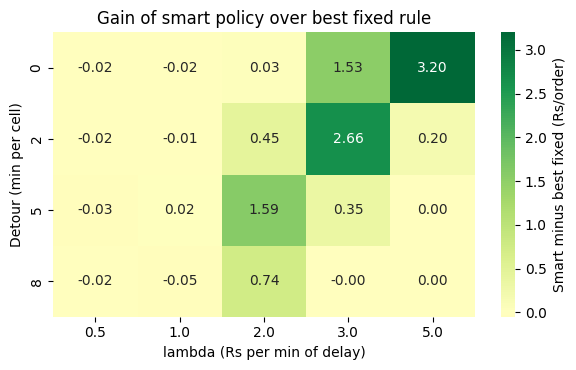

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import seaborn as sns
g = sens.pivot(index="detour", columns="lam", values="gain")
plt.figure(figsize=(6, 3.8))
sns.heatmap(g, annot=True, fmt=".2f", cmap="RdYlGn", center=0,
            cbar_kws={"label": "Smart minus best fixed (Rs/order)"})
plt.xlabel("lambda (Rs per min of delay)"); plt.ylabel("Detour (min per cell)")
plt.title("Gain of smart policy over best fixed rule")
plt.tight_layout(); plt.savefig("sensitivity_gain.png", dpi=200); plt.show()
files.download("sensitivity_gain.png")